In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

import json
import pickle
import torch

from scipy.stats import wilcoxon

# Compare best base models with FoMo-0D

24.10. model_24_10: SquareGMM of Simon, feat=70, inflate_full=True, delta=0.005, max_feature_dim=70, max_model_dim=70, prior.gmm.max_num_cluster=70, EPOCHS=50, BATCH_SIZE=6, nlayer=6, nhead=2,

---> BEST MODEL: model_24_10

In [27]:
#Fomo-0D model
default_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
default_dir_best_loss = "../ckpt/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/best.ckpt"

model_24_10_dir = "../results/adbench/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_24_10_train_val_loss_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/train_val_loss.pickle"
model_24_10_best_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/best.ckpt"
model_24_10_best_val_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/best_val.ckpt"
model_24_10_last_dir = "../ckpt/(BESTMODEL)dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/last.ckpt"


model_24_4_dir = "../results/adbench/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer5.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_24_4_train_val_loss_dir = "../ckpt/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer5.ndevice1/seed0/train_val_loss.pickle"

model_24_7_dir = "../results/adbench/dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters70/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_24_7_train_val_loss_dir = "../ckpt/dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters70/seed0/train_val_loss.pickle"

model_24_11_dir = "../results/adbench/dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.0003.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters70/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_24_11_train_val_loss_dir = "../ckpt/dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.0003.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters70/seed0/train_val_loss.pickle"

model_28_2_dir = "../results/adbench/dataSGMM.context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters60/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_28_2_train_val_loss_dir = "../ckpt/dataSGMM.context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters60/seed0/train_val_loss.pickle"

model_28_4_dir = "../results/adbench/dataSGMM.context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters70/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_28_4_train_val_loss_dir = "../ckpt/dataSGMM.context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters70/seed0/train_val_loss.pickle"

model_24_12_dir = "../results/adbench/dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.0003.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_24_12_train_val_loss_dir = "../ckpt/dataSGMM.context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.0003.emb256.hdim512.nhead2.nlayer6.ndevice1.numclusters70/seed0/train_val_loss.pickle"

model_28_3_dir = "../results/adbench/dataSGMM.context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters50/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_28_3_train_val_loss_dir = "../ckpt/dataSGMM.context5000.feat80.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer6.ndevice1.numclusters50/seed0/train_val_loss.pickle"

model_24_dir = "../results/adbench/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_24_train_val_loss_dir = "../ckpt/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs6.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"

model_22_dir = "../results/adbench/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_22_train_val_loss_dir = "../ckpt/context5000.feat70.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/train_val_loss.pickle"



### 1. Default model

In [28]:
default_aucroc_scores = []
default_aucpr_scores = []
default_f1_scores = []
datasets_name = []
default_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(default_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)

        # extract scores
        aucroc = df['aucroc'].values[0]
        default_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        default_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        default_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        default_time_per_instance.append(time_instance)

# compute average scores of all datasets
default_avg_aucroc = sum(default_aucroc_scores) / len(default_aucroc_scores)
default_avg_aucpr = sum(default_aucpr_scores) / len(default_aucpr_scores)
default_avg_f1 = sum(default_f1_scores) / len(default_f1_scores)
default_time_per_instance_avg = sum(default_time_per_instance) / len(default_time_per_instance)

print(f"number of datasets: {len(default_aucroc_scores)}")
print(f"Average aucroc: {default_avg_aucroc}")
print(f"Average aucpr: {default_avg_aucpr}")
print(f"Average f1: {default_avg_f1}")
print(f"Inference time per instance: {default_time_per_instance_avg}")

number of datasets: 121
Average aucroc: 0.7590645511541744
Average aucpr: 0.4786638498057685
Average f1: 0.4666975187169514
Inference time per instance: 0.004876898293420036


In [29]:
default_fomo_dict = {'dataset': datasets_name, 'aucroc': default_aucroc_scores, 'aucpr': default_aucpr_scores, 'f1': default_f1_scores}
default_fomo_df = pd.DataFrame(default_fomo_dict)
#default_fomo_df.to_csv('default_fomo_result.csv')

In [30]:
default_ckpt_best = torch.load(default_dir_best_loss, map_location="cpu")

default_train_loss = default_ckpt_best["train_losses"]
default_val_loss = default_ckpt_best["val_losses"]
default_last_lr = default_ckpt_best["lr_schedulers"][0]['_last_lr']

print(default_ckpt_best.keys())
print(default_ckpt_best["epoch"])


dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers', 'train_losses', 'val_losses'])
176


### 2. model_24_10 (best model - top1)

In [31]:
with open(model_24_10_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_24_10 = data["train_loss"]
val_loss_24_10 = data["val_loss"]
model_24_10_train_time = data['train_time']

print("Train time in second", model_24_10_train_time)

model_24_10_aucroc_scores = []
model_24_10_aucpr_scores = []
model_24_10_f1_scores = []
datasets_name = []
model_24_10_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_24_10_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_24_10_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_24_10_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_24_10_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_24_10_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_24_10_avg_aucroc = sum(model_24_10_aucroc_scores) / len(model_24_10_aucroc_scores)
model_24_10_avg_aucpr = sum(model_24_10_aucpr_scores) / len(model_24_10_aucpr_scores)
model_24_10_avg_f1 = sum(model_24_10_f1_scores) / len(model_24_10_f1_scores)
model_24_10_time_per_instance_avg = sum(model_24_10_time_per_instance) / len(model_24_10_time_per_instance)

print(f"number of datasets: {len(model_24_10_aucroc_scores)}")
print(f"Average aucroc: {model_24_10_avg_aucroc}")
print(f"Average aucpr: {model_24_10_avg_aucpr}")
print(f"Average f1: {model_24_10_avg_f1}")
print(f"Inference time per instance: {model_24_10_time_per_instance_avg}")

Train time in second 24182.45950436592
number of datasets: 121
Average aucroc: 0.7761609876983426
Average aucpr: 0.4592854784870678
Average f1: 0.46209364279753334
Inference time per instance: 7.158595120994333e-06


### 3. model_24_7 ( top2)

In [32]:
with open(model_24_7_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_24_7 = data["train_loss"]
val_loss_24_7 = data["val_loss"]
model_24_7_train_time = data['train_time']

print("Train time in second", model_24_7_train_time)

model_24_7_aucroc_scores = []
model_24_7_aucpr_scores = []
model_24_7_f1_scores = []
datasets_name = []
model_24_7_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_24_7_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_24_7_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_24_7_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_24_7_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_24_7_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_24_7_avg_aucroc = sum(model_24_7_aucroc_scores) / len(model_24_7_aucroc_scores)
model_24_7_avg_aucpr = sum(model_24_7_aucpr_scores) / len(model_24_7_aucpr_scores)
model_24_7_avg_f1 = sum(model_24_7_f1_scores) / len(model_24_7_f1_scores)
model_24_7_time_per_instance_avg = sum(model_24_7_time_per_instance) / len(model_24_7_time_per_instance)

print(f"number of datasets: {len(model_24_7_aucroc_scores)}")
print(f"Average aucroc: {model_24_7_avg_aucroc}")
print(f"Average aucpr: {model_24_7_avg_aucpr}")
print(f"Average f1: {model_24_7_avg_f1}")
print(f"Inference time per instance: {model_24_7_time_per_instance_avg}")

Train time in second 27932.195737600327
number of datasets: 121
Average aucroc: 0.774319716073919
Average aucpr: 0.45995260656357806
Average f1: 0.46053825797115905
Inference time per instance: 1.1264139905141553e-05


### 4. model_24_11 (top3)

In [33]:
with open(model_24_11_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_24_11 = data["train_loss"]
val_loss_24_11 = data["val_loss"]
model_24_11_train_time = data['train_time']

print("Train time in second", model_24_11_train_time)

model_24_11_aucroc_scores = []
model_24_11_aucpr_scores = []
model_24_11_f1_scores = []
datasets_name = []
model_24_11_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_24_11_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_24_11_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_24_11_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_24_11_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_24_11_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_24_11_avg_aucroc = sum(model_24_11_aucroc_scores) / len(model_24_11_aucroc_scores)
model_24_11_avg_aucpr = sum(model_24_11_aucpr_scores) / len(model_24_11_aucpr_scores)
model_24_11_avg_f1 = sum(model_24_11_f1_scores) / len(model_24_11_f1_scores)
model_24_11_time_per_instance_avg = sum(model_24_11_time_per_instance) / len(model_24_11_time_per_instance)

print(f"number of datasets: {len(model_24_11_aucroc_scores)}")
print(f"Average aucroc: {model_24_11_avg_aucroc}")
print(f"Average aucpr: {model_24_11_avg_aucpr}")
print(f"Average f1: {model_24_11_avg_f1}")
print(f"Inference time per instance: {model_24_11_time_per_instance_avg}")

Train time in second 22429.685249567032
number of datasets: 121
Average aucroc: 0.772429863640844
Average aucpr: 0.4612086666234587
Average f1: 0.4673611144741925
Inference time per instance: 7.074724005134603e-06


### 5. model_28_2 (top4)

In [34]:
with open(model_28_2_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_28_2 = data["train_loss"]
val_loss_28_2 = data["val_loss"]
model_28_2_train_time = data['train_time']

print("Train time in second", model_28_2_train_time)

model_28_2_aucroc_scores = []
model_28_2_aucpr_scores = []
model_28_2_f1_scores = []
datasets_name = []
model_28_2_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_28_2_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_28_2_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_28_2_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_28_2_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_28_2_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_28_2_avg_aucroc = sum(model_28_2_aucroc_scores) / len(model_28_2_aucroc_scores)
model_28_2_avg_aucpr = sum(model_28_2_aucpr_scores) / len(model_28_2_aucpr_scores)
model_28_2_avg_f1 = sum(model_28_2_f1_scores) / len(model_28_2_f1_scores)
model_28_2_time_per_instance_avg = sum(model_28_2_time_per_instance) / len(model_28_2_time_per_instance)

print(f"number of datasets: {len(model_28_2_aucroc_scores)}")
print(f"Average aucroc: {model_28_2_avg_aucroc}")
print(f"Average aucpr: {model_28_2_avg_aucpr}")
print(f"Average f1: {model_28_2_avg_f1}")
print(f"Inference time per instance: {model_28_2_time_per_instance_avg}")

Train time in second 32788.11220288277
number of datasets: 121
Average aucroc: 0.7721933743180663
Average aucpr: 0.45471994921474806
Average f1: 0.45864869625134047
Inference time per instance: 7.2416616100504255e-06


### 6. model_24_4 (top5)

In [35]:
with open(model_24_4_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_24_4 = data["train_loss"]
val_loss_24_4 = data["val_loss"]
model_24_4_train_time = data['train_time']

print("Train time in second", model_24_4_train_time)

model_24_4_aucroc_scores = []
model_24_4_aucpr_scores = []
model_24_4_f1_scores = []
datasets_name = []
model_24_4_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_24_4_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_24_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_24_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_24_4_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_24_4_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_24_4_avg_aucroc = sum(model_24_4_aucroc_scores) / len(model_24_4_aucroc_scores)
model_24_4_avg_aucpr = sum(model_24_4_aucpr_scores) / len(model_24_4_aucpr_scores)
model_24_4_avg_f1 = sum(model_24_4_f1_scores) / len(model_24_4_f1_scores)
model_24_4_time_per_instance_avg = sum(model_24_4_time_per_instance) / len(model_24_4_time_per_instance)

print(f"number of datasets: {len(model_24_4_aucroc_scores)}")
print(f"Average aucroc: {model_24_4_avg_aucroc}")
print(f"Average aucpr: {model_24_4_avg_aucpr}")
print(f"Average f1: {model_24_4_avg_f1}")
print(f"Inference time per instance: {model_24_4_time_per_instance_avg}")

Train time in second 21271.136691331863
number of datasets: 121
Average aucroc: 0.7715559735100019
Average aucpr: 0.45197850522681715
Average f1: 0.4573470384130845
Inference time per instance: 6.1063041432016e-06


### 7. model_28_4 (top6)

In [36]:
with open(model_28_4_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_28_4 = data["train_loss"]
val_loss_28_4 = data["val_loss"]
model_28_4_train_time = data['train_time']

print("Train time in second", model_28_4_train_time)

model_28_4_aucroc_scores = []
model_28_4_aucpr_scores = []
model_28_4_f1_scores = []
datasets_name = []
model_28_4_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_28_4_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_28_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_28_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_28_4_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_28_4_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_28_4_avg_aucroc = sum(model_28_4_aucroc_scores) / len(model_28_4_aucroc_scores)
model_28_4_avg_aucpr = sum(model_28_4_aucpr_scores) / len(model_28_4_aucpr_scores)
model_28_4_avg_f1 = sum(model_28_4_f1_scores) / len(model_28_4_f1_scores)
model_28_4_time_per_instance_avg = sum(model_28_4_time_per_instance) / len(model_28_4_time_per_instance)

print(f"number of datasets: {len(model_28_4_aucroc_scores)}")
print(f"Average aucroc: {model_28_4_avg_aucroc}")
print(f"Average aucpr: {model_28_4_avg_aucpr}")
print(f"Average f1: {model_28_4_avg_f1}")
print(f"Inference time per instance: {model_28_4_time_per_instance_avg}")

Train time in second 29073.448152542114
number of datasets: 121
Average aucroc: 0.7710384609359924
Average aucpr: 0.45244819787054963
Average f1: 0.452962565892872
Inference time per instance: 7.1515707618306695e-06


### 8. model_24_12 (top7)

In [37]:
with open(model_24_12_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_24_12 = data["train_loss"]
val_loss_24_12 = data["val_loss"]
model_24_12_train_time = data['train_time']

print("Train time in second", model_24_12_train_time)

model_24_12_aucroc_scores = []
model_24_12_aucpr_scores = []
model_24_12_f1_scores = []
datasets_name = []
model_24_12_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_24_12_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_24_12_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_24_12_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_24_12_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_24_12_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_24_12_avg_aucroc = sum(model_24_12_aucroc_scores) / len(model_24_12_aucroc_scores)
model_24_12_avg_aucpr = sum(model_24_12_aucpr_scores) / len(model_24_12_aucpr_scores)
model_24_12_avg_f1 = sum(model_24_12_f1_scores) / len(model_24_12_f1_scores)
model_24_12_time_per_instance_avg = sum(model_24_12_time_per_instance) / len(model_24_12_time_per_instance)

print(f"number of datasets: {len(model_24_12_aucroc_scores)}")
print(f"Average aucroc: {model_24_12_avg_aucroc}")
print(f"Average aucpr: {model_24_12_avg_aucpr}")
print(f"Average f1: {model_24_12_avg_f1}")
print(f"Inference time per instance: {model_24_12_time_per_instance_avg}")

Train time in second 18113.879534244537
number of datasets: 121
Average aucroc: 0.7704062895293013
Average aucpr: 0.4502169143643008
Average f1: 0.45499924966883143
Inference time per instance: 7.168655753855973e-06


### 9. model_28_3 (top8)

In [38]:
with open(model_28_3_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_28_3 = data["train_loss"]
val_loss_28_3 = data["val_loss"]
model_28_3_train_time = data['train_time']

print("Train time in second", model_28_3_train_time)

model_28_3_aucroc_scores = []
model_28_3_aucpr_scores = []
model_28_3_f1_scores = []
datasets_name = []
model_28_3_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_28_3_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_28_3_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_28_3_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_28_3_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_28_3_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_28_3_avg_aucroc = sum(model_28_3_aucroc_scores) / len(model_28_3_aucroc_scores)
model_28_3_avg_aucpr = sum(model_28_3_aucpr_scores) / len(model_28_3_aucpr_scores)
model_28_3_avg_f1 = sum(model_28_3_f1_scores) / len(model_28_3_f1_scores)
model_28_3_time_per_instance_avg = sum(model_28_3_time_per_instance) / len(model_28_3_time_per_instance)

print(f"number of datasets: {len(model_28_3_aucroc_scores)}")
print(f"Average aucroc: {model_28_3_avg_aucroc}")
print(f"Average aucpr: {model_28_3_avg_aucpr}")
print(f"Average f1: {model_28_3_avg_f1}")
print(f"Inference time per instance: {model_28_3_time_per_instance_avg}")

Train time in second 21985.195255994797
number of datasets: 121
Average aucroc: 0.770199823356046
Average aucpr: 0.4467507541176453
Average f1: 0.45023206644475705
Inference time per instance: 7.265605355897464e-06


### 9. model_24 (top9)

In [39]:
with open(model_24_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_24 = data["train_loss"]
val_loss_24 = data["val_loss"]
model_24_train_time = data['train_time']

print("Train time in second", model_24_train_time)

model_24_aucroc_scores = []
model_24_aucpr_scores = []
model_24_f1_scores = []
datasets_name = []
model_24_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_24_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_24_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_24_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_24_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_24_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_24_avg_aucroc = sum(model_24_aucroc_scores) / len(model_24_aucroc_scores)
model_24_avg_aucpr = sum(model_24_aucpr_scores) / len(model_24_aucpr_scores)
model_24_avg_f1 = sum(model_24_f1_scores) / len(model_24_f1_scores)
model_24_time_per_instance_avg = sum(model_24_time_per_instance) / len(model_24_time_per_instance)

print(f"number of datasets: {len(model_24_aucroc_scores)}")
print(f"Average aucroc: {model_24_avg_aucroc}")
print(f"Average aucpr: {model_24_avg_aucpr}")
print(f"Average f1: {model_24_avg_f1}")
print(f"Inference time per instance: {model_24_time_per_instance_avg}")

Train time in second 24438.818897247314
number of datasets: 121
Average aucroc: 0.7697659957547673
Average aucpr: 0.4490145093473653
Average f1: 0.4497923147876835
Inference time per instance: 5.1106435673690565e-06


### 11. model_22 (top10)

In [40]:
with open(model_22_train_val_loss_dir, "rb") as f:
    data = pickle.load(f)

train_loss_22 = data["train_loss"]
val_loss_22 = data["val_loss"]
model_22_train_time = data['train_time']

print("Train time in second", model_22_train_time)

model_22_aucroc_scores = []
model_22_aucpr_scores = []
model_22_f1_scores = []
datasets_name = []
model_22_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_22_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)
        # extract dataset name
        dataset_name = os.path.basename(os.path.dirname(subdir))
        datasets_name.append(dataset_name)
        
        # extract scores
        aucroc = df['aucroc'].values[0]
        model_22_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_22_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_22_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_22_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_22_avg_aucroc = sum(model_22_aucroc_scores) / len(model_22_aucroc_scores)
model_22_avg_aucpr = sum(model_22_aucpr_scores) / len(model_22_aucpr_scores)
model_22_avg_f1 = sum(model_22_f1_scores) / len(model_22_f1_scores)
model_22_time_per_instance_avg = sum(model_22_time_per_instance) / len(model_22_time_per_instance)

print(f"number of datasets: {len(model_22_aucroc_scores)}")
print(f"Average aucroc: {model_22_avg_aucroc}")
print(f"Average aucpr: {model_22_avg_aucpr}")
print(f"Average f1: {model_22_avg_f1}")
print(f"Inference time per instance: {model_22_time_per_instance_avg}")

Train time in second 17772.96105003357
number of datasets: 121
Average aucroc: 0.7692643131977385
Average aucpr: 0.44905888404148675
Average f1: 0.4493582619772472
Inference time per instance: 5.099698427791145e-06


### Scatter plot of two models:

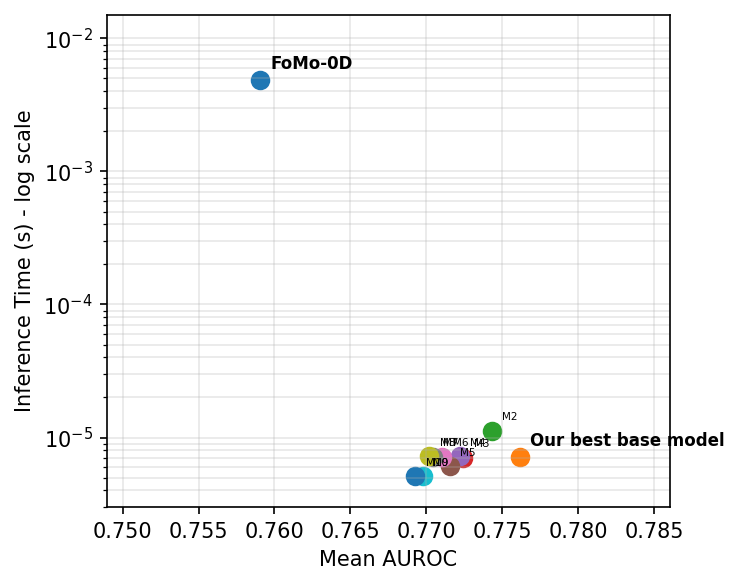

In [41]:
models = [
    ("FoMo-0D", 0.7590645511541744, 0.004876898293420036),
    ("Our best base model", model_24_10_avg_aucroc, model_24_10_time_per_instance_avg),
    ("M2", model_24_7_avg_aucroc, model_24_7_time_per_instance_avg),
    ("M3", model_24_11_avg_aucroc, model_24_11_time_per_instance_avg),
    ("M4", model_28_2_avg_aucroc, model_28_2_time_per_instance_avg),
    ("M5", model_24_4_avg_aucroc, model_24_4_time_per_instance_avg),
    ("M6", model_28_4_avg_aucroc, model_28_4_time_per_instance_avg),
    ("M7", model_24_12_avg_aucroc, model_24_12_time_per_instance_avg),
    ("M8", model_28_3_avg_aucroc, model_28_3_time_per_instance_avg),
    ("M9", model_24_avg_aucroc, model_24_time_per_instance_avg),
    ("M10", model_22_avg_aucroc, model_22_time_per_instance_avg),
]

fig, ax = plt.subplots(figsize=(5, 4), dpi=150)

# Scatter points
for name, auc, infer_time in models:
    # if (name == "FoMo-0D"):
    #     ax.scatter(auc, infer_time, s=70, color='blue')
    # else:
    #     ax.scatter(auc, infer_time, s=70)

    ax.scatter(auc, infer_time, s=70)
    if (name == "FoMo-0D") or (name == "Our best base model"):
        ax.annotate(
            name,
            (auc, infer_time),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
            fontweight="bold",
            #arrowprops=dict(arrowstyle="->", lw=0.9)
        )
    else:
        ax.annotate(
            name,
            (auc, infer_time),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=5,
            fontweight="light",
        )

ax.set_xlabel("Mean AUROC")
ax.set_ylabel("Inference Time (s) - log scale")
ax.set_yscale("log")
#ax.set_title("Model Comparison", fontsize=16, fontweight="bold")
ax.grid(True, which="both", alpha=0.3)

ax.set_xlim(0.749, 0.786)
ax.set_ylim(3e-6, 1.5e-2)
#ax.legend(['#features=100, #epochs=200, #batch=8', 'test'])

plt.tight_layout()

#plt.savefig('fomo_top10_best_model_auroc.png', dpi=300, bbox_inches='tight')
plt.show()

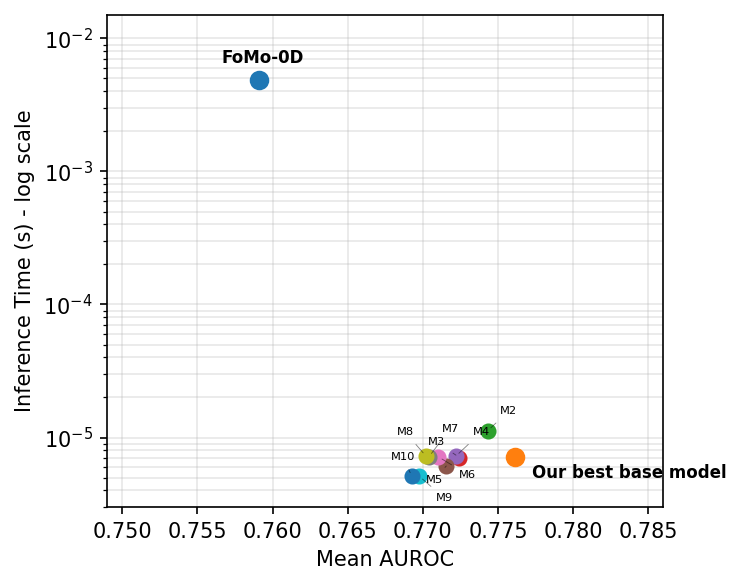

In [42]:
label_offsets = {
    "FoMo-0D": (-18, 8),
    "Our best base model": (8, -10),
    "M2": (6, 8),
    "M3": (-15, 6),
    "M4": (8, 10),
    "M5": (-10, -8),
    "M6": (10, -10),
    "M7": (6, 12),
    "M8": (-14, 10),
    "M9": (8, -12),
    "M10": (-10, 8),
}

fig, ax = plt.subplots(figsize=(5, 4), dpi=150)

for name, auc, infer_time in models:
    is_highlight = name in {"FoMo-0D", "Our best base model"}
    dx, dy = label_offsets.get(name, (6, 8))

    ax.scatter(auc, infer_time, s=70 if is_highlight else 45, zorder=3)
    ax.annotate(
        name,
        (auc, infer_time),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=8 if is_highlight else 5.5,
        fontweight="bold" if is_highlight else "normal",
        arrowprops=dict(arrowstyle="-", lw=0.4, alpha=0.5) if not is_highlight else None,
        zorder=4
    )

ax.set_xlabel("Mean AUROC")
ax.set_ylabel("Inference Time (s) - log scale")
ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.3, zorder=0)
ax.set_xlim(0.749, 0.786)
ax.set_ylim(3e-6, 1.5e-2)

plt.tight_layout()
plt.show()

### P-value of default_fomo and model_24_10(best_model)  (over 121 datasets)

In [43]:
model_24_10_result = pd.read_csv('model_24_10_result.csv')
default_fomo_result = pd.read_csv('default_fomo_result.csv')

In [44]:
import numpy as np
from scipy.stats import wilcoxon
model_24_10_auc, default_fomo_auc = [], []
for ds, auc, default in zip(model_24_10_result["dataset"],model_24_10_result["aucroc"], default_fomo_result['aucroc']):
    model_24_10_auc.append(auc)
    default_fomo_auc.append(default)

model_24_10_auc = np.array(model_24_10_auc)
default_fomo_auc = np.array(default_fomo_auc)

# Check differences
diffs = model_24_10_auc - default_fomo_auc
print("Mean improvement:", np.mean(diffs))
print("Better ratio:", np.mean(diffs > 0))

# One-sided Wilcoxon test
stat, p_value = wilcoxon(model_24_10_auc, default_fomo_auc, alternative='greater')

print("Statistic:", stat)
print("p-value:", p_value)
print(f"mean value of mode_24_10 vs. fomo-0D: {np.mean(model_24_10_auc)} vs. {np.mean(default_fomo_auc)}")  

Mean improvement: 0.017096436544167908
Better ratio: 0.4628099173553719
Statistic: 3996.0
p-value: 0.09615333781230967
mean value of mode_24_10 vs. fomo-0D: 0.7761609876983423 vs. 0.7590645511541743


The model shows a small average improvement in AUC (+0.017) and outperforms the baseline on 58% of datasets. However, the difference is not statistically significant (Wilcoxon signed-rank test, p = 0.127)

In [45]:
# # new files:
# model_24_10_result = pd.read_csv('processed_model_24_10_results.csv')
# default_fomo_result = pd.read_csv('processed_default_fomo.csv')

# model_24_10_auc, default_fomo_auc = [], []
# for ds, auc, default in zip(model_24_10_result["dataset"],model_24_10_result["aucroc"], default_fomo_result['aucroc']):
#     model_24_10_auc.append(auc)
#     default_fomo_auc.append(default)

# model_24_10_auc = np.array(model_24_10_auc)
# default_fomo_auc = np.array(default_fomo_auc)

# # Check differences
# diffs = model_24_10_auc - default_fomo_auc
# print("Mean improvement:", np.mean(diffs))
# print("Better ratio:", np.mean(diffs > 0))

# # One-sided Wilcoxon test
# stat, p_value = wilcoxon(model_24_10_auc, default_fomo_auc, alternative='greater')

# print("Statistic:", stat)
# print("p-value:", p_value)

### Compare against some high dimensional datasets

In [46]:
# Image
CIFAR10 = ['CIFAR10_0', 'CIFAR10_1', 'CIFAR10_2', 'CIFAR10_3', 'CIFAR10_4', 'CIFAR10_5', 'CIFAR10_6', 'CIFAR10_7', 'CIFAR10_8', 'CIFAR10_9']
FashionMNIST = ['FashionMNIST_0', 'FashionMNIST_1', 'FashionMNIST_2', 'FashionMNIST_3', 'FashionMNIST_4', 'FashionMNIST_5', 'FashionMNIST_6', 'FashionMNIST_7', 'FashionMNIST_8', 'FashionMNIST_9']
MNIST_C = ['MNIST-C_brightness', 'MNIST-C_canny_edges', 'MNIST-C_dotted_line', 'MNIST-C_fog', 'MNIST-C_glass_blur', 'MNIST-C_identity', 
           'MNIST-C_impulse_noise', 'MNIST-C_motion_blur', 'MNIST-C_rotate', 'MNIST-C_scale', 'MNIST-C_shear', 'MNIST-C_shot_noise', 
           'MNIST-C_spatter', 'MNIST-C_stripe', 'MNIST-C_translate', 'MNIST-C_zigzag']
MVTec_AD = ['MVTec-AD_bottle', 'MVTec-AD_cable', 'MVTec-AD_capsule', 'MVTec-AD_carpet', 'MVTec-AD_grid', 'MVTec-AD_hazelnut', 'MVTec-AD_leather', 
            'MVTec-AD_metal_nut', 'MVTec-AD_pill', 'MVTec-AD_screw', 'MVTec-AD_tile', 'MVTec-AD_toothbrush', 'MVTec-AD_transistor', 'MVTec-AD_wood', 'MVTec-AD_zipper']

SVHN = ['SVHN_0', 'SVHN_1', 'SVHN_2', 'SVHN_3', 'SVHN_4', 'SVHN_5', 'SVHN_6', 'SVHN_7', 'SVHN_8', 'SVHN_9']

In [47]:
# NLP
agnews = ['agnews_0', 'agnews_1', 'agnews_2', 'agnews_3']
amazon = ['amazon']
Imdb = ['imdb']
Yelp = ['yelp']
test_20newsgroups = ['20news_0', '20news_1', '20news_2', '20news_3', '20news_4', '20news_5']

### Group Image

##### 1. CIFAR10

In [48]:
default_CIFAR10 = []
base_model_CIFAR10 = []
for item in CIFAR10:
    default_CIFAR10.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_CIFAR10.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

CIFAR10_dict = {'dataset': CIFAR10, 'default_CIFAR10': default_CIFAR10, 'model_24_10_CIFAR10': base_model_CIFAR10}
CIFAR10_df = pd.DataFrame(CIFAR10_dict)
CIFAR10_df

NameError: name 'model_24_10_df' is not defined

##### 2. FashionMNIST

In [26]:
default_FashionMNIST = []
base_model_FashionMNIST = []
for item in FashionMNIST:
    default_FashionMNIST.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_FashionMNIST.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

FashionMNIST_dict = {'dataset': FashionMNIST, 'default_FashionMNIST': default_FashionMNIST, 'model_24_10_FashionMNIST': base_model_FashionMNIST}
FashionMNIST_df = pd.DataFrame(FashionMNIST_dict)
FashionMNIST_df

NameError: name 'model_24_10_df' is not defined

##### 3. MNIST_C

In [21]:
default_MNIST_C = []
base_model_MNIST_C = []
for item in MNIST_C:
    default_MNIST_C.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_MNIST_C.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

MNIST_C_dict = {'dataset': MNIST_C, 'default_MNIST_C': default_MNIST_C, 'model_24_10_MNIST_C': base_model_MNIST_C}
MNIST_C_df = pd.DataFrame(MNIST_C_dict)
MNIST_C_df

,dataset,default_MNIST_C,model_24_10_MNIST_C
0,MNIST-C_brightness,0.732662,0.815336
1,MNIST-C_canny_edges,0.838866,0.849418
2,MNIST-C_dotted_line,0.795969,0.764500
3,MNIST-C_fog,0.937361,0.946931
4,MNIST-C_glass_blur,0.946622,0.902214
5,MNIST-C_identity,0.470528,0.482561
6,MNIST-C_impulse_noise,0.999925,0.995048
7,MNIST-C_motion_blur,0.819526,0.879562
8,MNIST-C_rotate,0.547304,0.598710
9,MNIST-C_scale,0.694694,0.883920


##### 4. MVTec_AD

In [24]:
default_MVTec_AD = []
base_model_MVTec_AD = []
for item in MVTec_AD:
    default_MVTec_AD.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_MVTec_AD.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

MVTec_AD_dict = {'dataset': MVTec_AD, 'default_MVTec_AD': default_MVTec_AD, 'model_24_10_MVTec_AD': base_model_MVTec_AD}
MVTec_AD_df = pd.DataFrame(MVTec_AD_dict)
MVTec_AD_df

,dataset,default_MVTec_AD,model_24_10_MVTec_AD
0,MVTec-AD_bottle,0.971409,0.996197
1,MVTec-AD_cable,0.716171,0.939546
2,MVTec-AD_capsule,0.613014,0.827005
3,MVTec-AD_carpet,0.718359,0.871997
4,MVTec-AD_grid,0.658397,0.888249
5,MVTec-AD_hazelnut,0.644551,0.859767
6,MVTec-AD_leather,0.968578,0.963761
7,MVTec-AD_metal_nut,0.780553,0.852451
8,MVTec-AD_pill,0.762669,0.872589
9,MVTec-AD_screw,0.521039,0.738385


##### 5. SVHN

In [25]:
default_SVHN = []
base_model_SVHN = []
for item in SVHN:
    default_SVHN.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_SVHN.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

SVHN_dict = {'dataset': SVHN, 'default_SVHN': default_SVHN, 'model_24_10_SVHN': base_model_SVHN}
SVHN_df = pd.DataFrame(SVHN_dict)
SVHN_df

,dataset,default_SVHN,model_24_10_SVHN
0,SVHN_0,0.575946,0.536363
1,SVHN_1,0.595887,0.534543
2,SVHN_2,0.640147,0.636998
3,SVHN_3,0.616290,0.652900
4,SVHN_4,0.587366,0.618327
5,SVHN_5,0.661108,0.672675
6,SVHN_6,0.540792,0.559945
7,SVHN_7,0.594488,0.598566
8,SVHN_8,0.563458,0.578180
9,SVHN_9,0.568964,0.543195


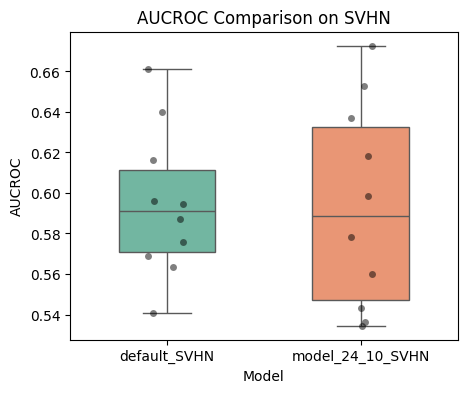

In [31]:
SVHN_melted = SVHN_df.melt(
    id_vars='dataset',
    value_vars=['default_SVHN', 'model_24_10_SVHN'],
    var_name='model',
    value_name='aucroc'
)
plt.figure(figsize=(5, 4))
#sns.boxplot(data=SVHN_melted, x='model', y='aucroc')
sns.boxplot(data=SVHN_melted, x='model', y='aucroc', hue="model", palette="Set2", legend='auto', width=0.5)
sns.stripplot(data=SVHN_melted, x='model', y='aucroc', color='black', alpha=0.5)

plt.title('AUCROC Comparison on SVHN')
plt.xlabel('Model')
plt.ylabel('AUCROC')

plt.show()
#plt.savefig('data_priors_impact.png', dpi=300, bbox_inches='tight')

In [17]:
# Add a column telling which dataset-group each dataframe belongs to
CIFAR10_plot = CIFAR10_df.rename(columns={
    'default_CIFAR10': 'FoMo-0D',
    'model_24_10_CIFAR10': 'Our base model'
}).copy()
CIFAR10_plot['group'] = 'CIFAR10'

FashionMNIST_plot = FashionMNIST_df.rename(columns={
    'default_FashionMNIST': 'FoMo-0D',
    'model_24_10_FashionMNIST': 'Our base model'
}).copy()
FashionMNIST_plot['group'] = 'FashionMNIST'

MNIST_C_plot = MNIST_C_df.rename(columns={
    'default_MNIST_C': 'FoMo-0D',
    'model_24_10_MNIST_C': 'Our base model'
}).copy()
MNIST_C_plot['group'] = 'MNIST_C'

MVTec_AD_plot = MVTec_AD_df.rename(columns={
    'default_MVTec_AD': 'FoMo-0D',
    'model_24_10_MVTec_AD': 'Our base model'
}).copy()
MVTec_AD_plot['group'] = 'MVTec_AD'

SVHN_plot = SVHN_df.rename(columns={
    'default_SVHN': 'FoMo-0D',
    'model_24_10_SVHN': 'Our base model'
}).copy()
SVHN_plot['group'] = 'SVHN'

# Combine all 5 dataframes
all_df = pd.concat(
    [CIFAR10_plot, FashionMNIST_plot, MNIST_C_plot, MVTec_AD_plot, SVHN_plot],
    ignore_index=True
)

# Convert from wide to long format
plot_df = all_df.melt(
    id_vars=['dataset', 'group'],
    value_vars=['FoMo-0D', 'Our base model'],
    var_name='model',
    value_name='aucroc'
)



NameError: name 'CIFAR10_df' is not defined

In [18]:
#plt.figure(figsize=(10, 5))
g = sns.catplot(
    data=plot_df,
    x='model',
    y='aucroc',
    col='group',
    kind='box',
    hue='model', palette="husl", legend='auto', width=0.5,
    col_wrap=5,
    height=4,
    aspect=0.6,
    showfliers=False
)

# Add points on top of each facet
g.map_dataframe(
    sns.stripplot,
    x='model',
    y='aucroc',
    color='black',
    alpha=0.5,
    jitter=True
)

g.set_axis_labels("model", "aucroc")
g.set_titles("dataset = {col_name}")
#g.fig.set_size_inches(16, 4)
#plt.savefig('image_datasets_fomo_best_model.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'plot_df' is not defined

### group NLP

##### 1. agnews

In [14]:
default_agnews = []
base_model_agnews = []
for item in agnews:
    default_agnews.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_agnews.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

agnews_dict = {'dataset': agnews, 'default_agnews': default_agnews, 'model_24_10_agnews': base_model_agnews}
agnews_df = pd.DataFrame(agnews_dict)
agnews_df


,dataset,default_agnews,model_24_10_agnews
0,agnews_0,0.578405,0.608261
1,agnews_1,0.587309,0.716865
2,agnews_2,0.702509,0.766122
3,agnews_3,0.568240,0.675795


##### 2. amazon

In [15]:
default_amazon = []
base_model_amazon = []
for item in amazon:
    default_amazon.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_amazon.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

amazon_dict = {'dataset': amazon, 'default_amazon': default_amazon, 'model_24_10_amazon': base_model_amazon}
amazon_df = pd.DataFrame(amazon_dict)
amazon_df

,dataset,default_amazon,model_24_10_amazon
0,amazon,0.49657,0.548579


##### 3. Imdb

In [17]:
default_imdb = []
base_model_imdb = []
for item in Imdb:
    default_imdb.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_imdb.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

imdb_dict = {'dataset': Imdb, 'default_imdb': default_imdb, 'model_24_10_imdb': base_model_imdb}
imdb_df = pd.DataFrame(imdb_dict)
imdb_df

,dataset,default_imdb,model_24_10_imdb
0,imdb,0.446315,0.489552


##### 4. yelp

In [75]:
default_yelp = []
base_model_yelp = []
for item in Yelp:
    default_yelp.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_yelp.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

yelp_dict = {'dataset': Yelp, 'default_yelp': default_yelp, 'model_24_10_yelp': base_model_yelp}
yelp_df = pd.DataFrame(yelp_dict)
yelp_df

,dataset,default_yelp,model_24_10_yelp
0,yelp,0.571992,0.643195


##### 2. 20newsgroups

In [77]:
default_20newsgroups = []
base_model_20newsgroups = []
for item in test_20newsgroups:
    default_20newsgroups.append(default_fomo_df[default_fomo_df['dataset'] == item]['aucroc'].values[0])
    base_model_20newsgroups.append(model_24_10_df[model_24_10_df['dataset'] == item]['aucroc'].values[0])

test_20newsgroups_dict = {'dataset': test_20newsgroups, 'default_20newsgroups': default_20newsgroups, 'model_24_10_20newsgroups': base_model_20newsgroups}
test_20newsgroups_df = pd.DataFrame(test_20newsgroups_dict)
test_20newsgroups_df

,dataset,default_20newsgroups,model_24_10_20newsgroups
0,20news_0,0.643426,0.746532
1,20news_1,0.510875,0.515474
2,20news_2,0.514481,0.501631
3,20news_3,0.773958,0.832611
4,20news_4,0.582282,0.560743
5,20news_5,0.531051,0.538733


In [78]:
# Add a column telling which dataset-group each dataframe belongs to
agnews_plot = agnews_df.rename(columns={
    'default_agnews': 'FoMo-0D',
    'model_24_10_agnews': 'Our base model'
}).copy()
agnews_plot['group'] = 'Agnews'

amazon_plot = amazon_df.rename(columns={
    'default_amazon': 'FoMo-0D',
    'model_24_10_amazon': 'Our base model'
}).copy()
amazon_plot['group'] = 'Amazon'

imdb_plot = imdb_df.rename(columns={
    'default_imdb': 'FoMo-0D',
    'model_24_10_imdb': 'Our base model'
}).copy()
imdb_plot['group'] = 'Imdb'

yelp_plot = yelp_df.rename(columns={
    'default_yelp': 'FoMo-0D',
    'model_24_10_yelp': 'Our base model'
}).copy()
yelp_plot['group'] = 'Yelp'

test_20newsgroups_plot = test_20newsgroups_df.rename(columns={
    'default_20newsgroups': 'FoMo-0D',
    'model_24_10_20newsgroups': 'Our base model'
}).copy()
test_20newsgroups_plot['group'] = '20newsgroups'

# Combine all 5 dataframes
all_df = pd.concat(
    [agnews_plot, amazon_plot, imdb_plot, yelp_plot, test_20newsgroups_plot],
    ignore_index=True
)

# Convert from wide to long format
plot_df = all_df.melt(
    id_vars=['dataset', 'group'],
    value_vars=['FoMo-0D', 'Our base model'],
    var_name='model',
    value_name='aucroc'
)

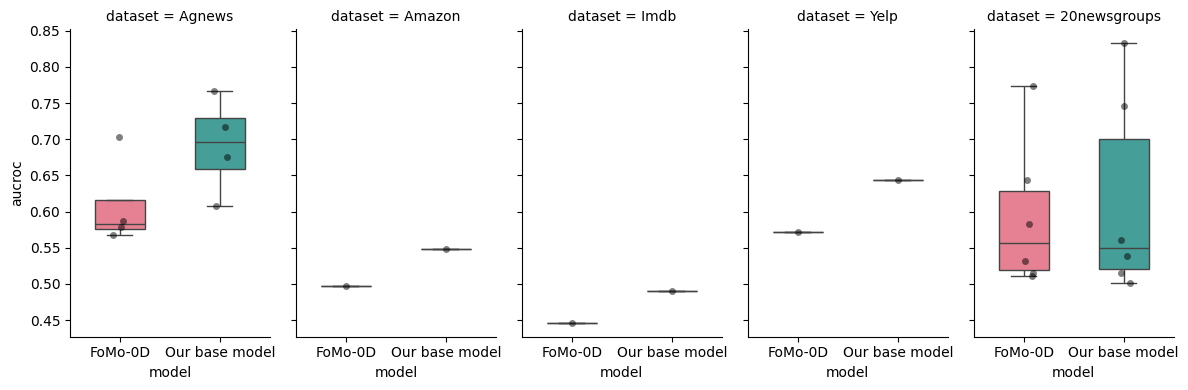

In [ ]:
g = sns.catplot(
    data=plot_df,
    x='model',
    y='aucroc',
    col='group',
    kind='box',
    hue='model', palette="husl", legend='auto', width=0.5,
    col_wrap=5,
    height=4,
    aspect=0.6,
    showfliers=False
)

# Add points on top of each facet
g.map_dataframe(
    sns.stripplot,
    x='model',
    y='aucroc',
    color='black',
    alpha=0.5,
    jitter=True
)

g.set_axis_labels("model", "aucroc")
g.set_titles("dataset = {col_name}")
#g.fig.set_size_inches(16, 4)
#plt.savefig('nlp_datasets_fomo_best_model.png', dpi=300, bbox_inches='tight')
plt.show()